In [2]:
import matplotlib.pyplot as plt
import numpy as np
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import mnist

# Two Layer Neural Network

In [3]:
class TwoLayerKeras:
    def __init__(self, input_size=784, hidden_size=100, output_size=10):
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.output_size = output_size

    def create_nn(self):
        self.model = keras.Sequential(
            [
                # H1
                layers.Dense(
                    self.hidden_size, activation="relu", input_shape=(self.input_size,)
                ),
                layers.Dense(self.hidden_size, activation="relu"),
                # output
                layers.Dense(self.output_size, activation="softmax"),
            ]
        )
        self.model.compile(
            optimizer="rmsprop",
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"],
        )
        print("Model: ", self.model.summary())

In [4]:
NN = TwoLayerKeras()
NN.create_nn()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 100)               78500     
                                                                 
 dense_1 (Dense)             (None, 100)               10100     
                                                                 
 dense_2 (Dense)             (None, 10)                1010      
                                                                 
Total params: 89610 (350.04 KB)
Trainable params: 89610 (350.04 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________
Model:  None


# Load Dataset

In [5]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("Original shapes:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test :", X_test.shape)
print("y_test :", y_test.shape)

X_train = X_train.reshape(60000, 784).astype("float32") / 255.0
X_test = X_test.reshape(10000, 784).astype("float32") / 255.0

# One-hot encoding
y_train_onehot = np.eye(10)[y_train]
y_test_onehot = np.eye(10)[y_test]

Original shapes:
X_train: (60000, 28, 28)
y_train: (60000,)
X_test : (10000, 28, 28)
y_test : (10000,)


# Training

In [6]:
history = NN.model.fit(X_train, y_train, epochs=10, batch_size=64, validation_split=0.2)

Epoch 1/10
750/750 [==============================] - 1s 704us/step - loss: 0.2999 - accuracy: 0.9130 - val_loss: 0.1454 - val_accuracy: 0.9573
Epoch 2/10
750/750 [==============================] - 1s 696us/step - loss: 0.1303 - accuracy: 0.9613 - val_loss: 0.1550 - val_accuracy: 0.9529
Epoch 3/10
750/750 [==============================] - 0s 666us/step - loss: 0.0928 - accuracy: 0.9724 - val_loss: 0.1212 - val_accuracy: 0.9649
Epoch 4/10
750/750 [==============================] - 0s 612us/step - loss: 0.0714 - accuracy: 0.9782 - val_loss: 0.1044 - val_accuracy: 0.9705
Epoch 5/10
750/750 [==============================] - 0s 664us/step - loss: 0.0566 - accuracy: 0.9830 - val_loss: 0.1030 - val_accuracy: 0.9741
Epoch 6/10
750/750 [==============================] - 0s 640us/step - loss: 0.0478 - accuracy: 0.9857 - val_loss: 0.1067 - val_accuracy: 0.9715
Epoch 7/10
750/750 [==============================] - 0s 627us/step - loss: 0.0402 - accuracy: 0.9879 - val_loss: 0.1037 - val_accuracy:

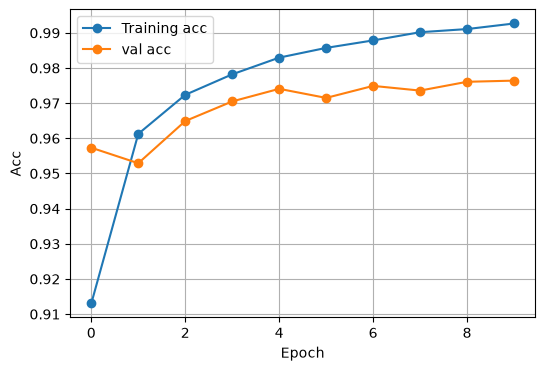

In [7]:
plt.figure(figsize=(6, 4))
plt.plot(history.history["accuracy"], marker="o", label="Training acc")
plt.plot(history.history["val_accuracy"], marker="o", label="val acc")
plt.xlabel("Epoch")
plt.ylabel("Acc")
plt.legend()
plt.grid()

# Test

In [8]:
predictions = NN.model.predict(X_test)
pred_class = np.argmax(predictions, axis=1)

test_acc = np.mean(y_test == pred_class)
print("Test acc: ", test_acc)

313/313 [==============================] - 0s 261us/step
Test acc:  0.9772
